In [49]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
import re

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split,
    GridSearchCV,
)
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score, log_loss
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier

import warnings

warnings.filterwarnings("ignore")

In [12]:
file_path = "food_reviews.csv"
data = pd.read_csv(file_path, usecols=[3, 4], header=0, names=["label", "text"])

In [13]:
data.head()

,label,text
0,positive,I have bought several of the Vitality canned d...
1,negative,Product arrived labeled as Jumbo Salted Peanut...
2,neutral,This is a confection that has been around a fe...
3,neutral,If you are looking for the secret ingredient i...
4,positive,Great taffy at a great price. There was a wid...


In [14]:
label2id = {"negative": 0, "neutral": 1, "positive": 2}
id2label = {0: "negative", 1: "neutral", 2: "positive"}
data["label"] = data["label"].map(label2id)

In [15]:
data.head()

,label,text
0,2,I have bought several of the Vitality canned d...
1,0,Product arrived labeled as Jumbo Salted Peanut...
2,1,This is a confection that has been around a fe...
3,1,If you are looking for the secret ingredient i...
4,2,Great taffy at a great price. There was a wid...


In [16]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


print("Выполняем предобработку текстов.")
data["clean_text"] = data["text"].apply(clean_text)

Выполняем предобработку текстов.


In [17]:
data.head()

,label,text,clean_text
0,2,I have bought several of the Vitality canned d...,i have bought several of the vitality canned d...
1,0,Product arrived labeled as Jumbo Salted Peanut...,product arrived labeled as jumbo salted peanut...
2,1,This is a confection that has been around a fe...,this is a confection that has been around a fe...
3,1,If you are looking for the secret ingredient i...,if you are looking for the secret ingredient i...
4,2,Great taffy at a great price. There was a wid...,great taffy at a great price there was a wide ...


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    data["clean_text"],
    data["label"],
    test_size=0.3,
    random_state=42,
    stratify=data["label"],
)

In [ ]:
print(f"Размеры выборок: Train={len(X_train)}, Test={len(X_test)}")

Размеры выборок: Train=10983, Test=4708


In [20]:
vectorizer = CountVectorizer(
    ngram_range=(1, 2), max_features=10000, min_df=2, max_df=0.95, stop_words=None
)

In [21]:
print("Векторизация текстов.")
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

Векторизация текстов.


In [22]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=50, learning_rate=0.1, random_state=42
    ),
}

In [23]:
results = []

print("Запуск обучения моделей.")
print("-" * 60)
print(f"{'Model':<20} | {'Test Accuracy':<12} | {'Test Log Loss':<12}")
print("-" * 60)

for name, model in models.items():
    model.fit(X_train_vec, y_train)
    y_pred = model.predict(X_test_vec)
    y_proba = model.predict_proba(X_test_vec)
    acc = accuracy_score(y_test, y_pred)
    ll = log_loss(y_test, y_proba)

    results.append({"Model": name, "Accuracy": acc, "Log Loss": ll, "Object": model})
    print(f"{name:<20} | {acc:.4f}       | {ll:.4f}")

Запуск обучения моделей.
------------------------------------------------------------
Model                | Test Accuracy | Test Log Loss
------------------------------------------------------------
Naive Bayes          | 0.7375       | 1.8830
Logistic Regression  | 0.7472       | 0.9051
Decision Tree        | 0.6415       | 0.8674
Gradient Boosting    | 0.7043       | 0.6972


In [24]:
best_result = sorted(results, key=lambda x: x["Accuracy"], reverse=True)[0]
best_model = best_result["Object"]

In [25]:
print(f"Лучшая модель на тесте: {best_result['Model']}")

Лучшая модель на тесте: Logistic Regression


In [ ]:
pipeline = Pipeline(
    [
        (
            "vectorizer",
            CountVectorizer(
                ngram_range=(1, 2), max_features=10000, min_df=2, max_df=0.95
            ),
        ),
        (
            "classifier",
            LogisticRegression(max_iter=1000, solver="lbfgs", C=1.0, random_state=42),
        ),
    ]
)

In [ ]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "log_loss": "neg_log_loss"}

print(f"Запуск кросс-валидации на 5 фолдах.")

cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring=scoring,
    return_train_score=False,
)

Запуск кросс-валидации на 5 фолдах.


In [ ]:
mean_acc = cv_results["test_accuracy"].mean()
std_acc = cv_results["test_accuracy"].std()

mean_ll = -cv_results["test_log_loss"].mean()
std_ll = cv_results["test_log_loss"].std()

print("Результаты Cross-Validation (на Train данных)")
print(f"Accuracy:  {mean_acc:.4f}  (±{std_acc:.4f})")
print(f"Log Loss:  {mean_ll:.4f}  (±{std_ll:.4f})")

Результаты Cross-Validation (на Train данных)
Accuracy:  0.7390  (±0.0084)
Log Loss:  0.9233  (±0.0247)


In [ ]:
param_grid = {
    "vectorizer__ngram_range": [(1, 1), (1, 2)],
    "vectorizer__max_features": [5000, 10000],
    "classifier__C": [0.1, 1.0, 10.0],
    "classifier__penalty": ["l1", "l2"],
}

In [32]:
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv_strategy,
    scoring="accuracy",
    refit="accuracy",
    n_jobs=-1,
    verbose=1,
)

print("Начинаем поиск лучших параметров.")
grid_search.fit(X_train, y_train)

Начинаем поиск лучших параметров.
Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.1, 1.0, ...], 'classifier__penalty': ['l1', 'l2'], 'vectorizer__max_features': [5000, 10000], 'vectorizer__ngram_range': [(1, ...), (1, ...)]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the 

In [33]:
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучшая точность на кросс-валидации: {grid_search.best_score_:.4f}")

best_model = grid_search.best_estimator_
test_pred = best_model.predict(X_test)
test_proba = best_model.predict_proba(X_test)

final_acc = accuracy_score(y_test, test_pred)
final_ll = log_loss(y_test, test_proba)

print("\n=== Результат лучшей модели на Test Set ===")
print(f"Test Accuracy: {final_acc:.4f}")
print(f"Test Log Loss: {final_ll:.4f}")

Лучшие параметры: {'classifier__C': 0.1, 'classifier__penalty': 'l2', 'vectorizer__max_features': 10000, 'vectorizer__ngram_range': (1, 2)}
Лучшая точность на кросс-валидации: 0.7543

=== Результат лучшей модели на Test Set ===
Test Accuracy: 0.7566
Test Log Loss: 0.6308


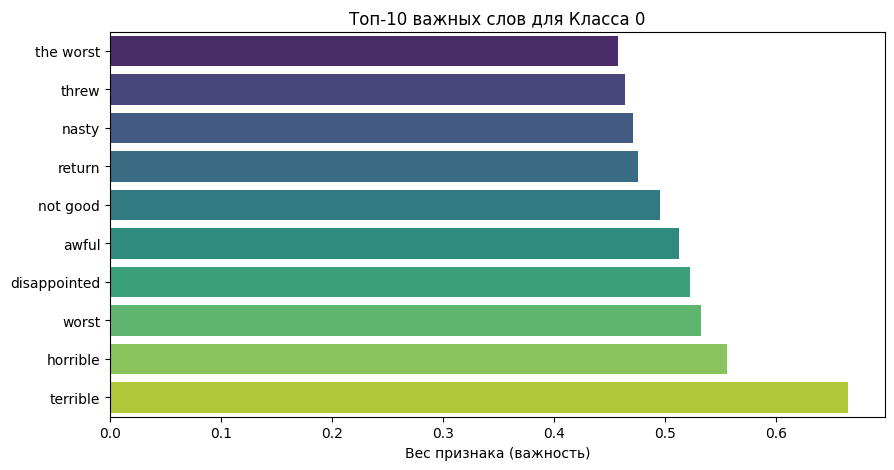

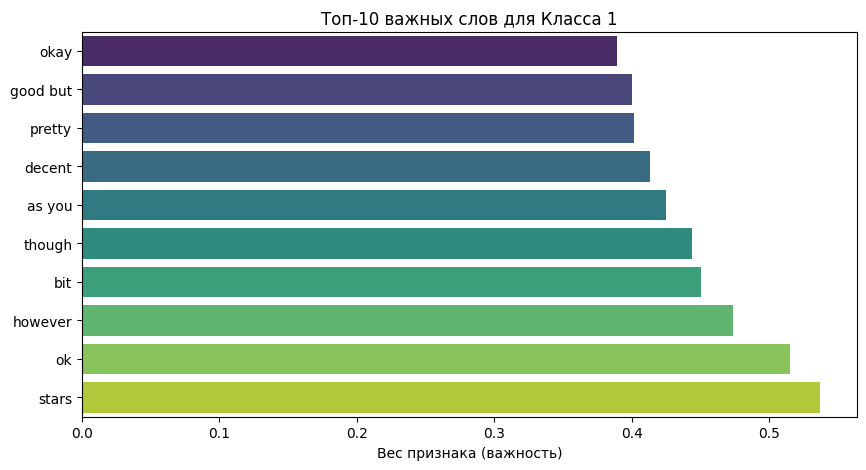

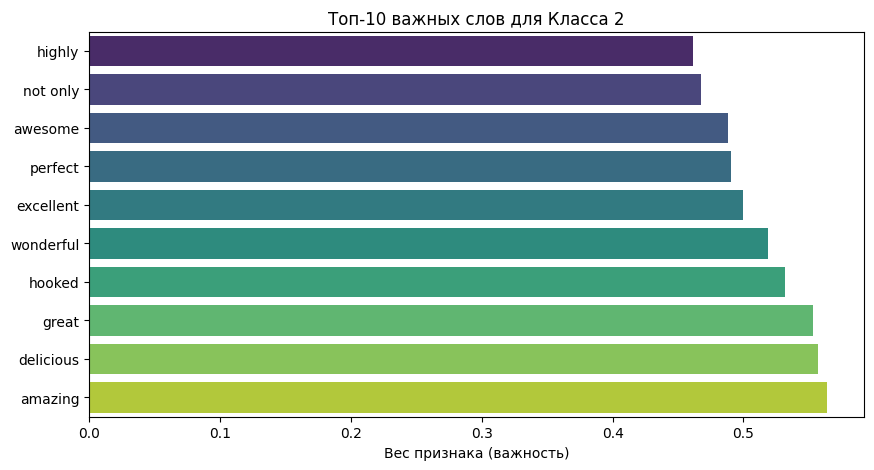

In [ ]:
def plot_top_features(grid_result, n_top=10):
    vectorizer = grid_result.best_estimator_.named_steps["vectorizer"]
    classifier = grid_result.best_estimator_.named_steps["classifier"]

    feature_names = vectorizer.get_feature_names_out()

    for i, class_label in enumerate(classifier.classes_):
        coefs = classifier.coef_[i]
        top_indices = np.argsort(coefs)[-n_top:]
        top_features = [feature_names[idx] for idx in top_indices]
        top_weights = coefs[top_indices]
        plt.figure(figsize=(10, 5))
        sns.barplot(x=top_weights, y=top_features, palette="viridis")
        plt.title(f"Топ-{n_top} важных слов для Класса {class_label}")
        plt.xlabel("Вес признака (важность)")
        plt.show()


plot_top_features(grid_search)

# TF-IDF


In [ ]:
pipeline_tfidf = Pipeline(
    [
        ("vectorizer", TfidfVectorizer(max_df=0.95, min_df=2)),
        (
            "classifier",
            LogisticRegression(max_iter=1000, solver="lbfgs", random_state=42),
        ),
    ]
)

In [ ]:
param_grid_tfidf = {
    "vectorizer__ngram_range": [(1, 1), (1, 2)],
    "vectorizer__use_idf": [True, False],
    "vectorizer__norm": ["l1", "l2"],
    "classifier__C": [0.1, 1.0, 10.0],
    "classifier__penalty": ["l1", "l2"],
}

In [ ]:
grid_tfidf = GridSearchCV(
    pipeline_tfidf,
    param_grid_tfidf,
    cv=cv_strategy,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1,
)

grid_tfidf.fit(X_train, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.1, 1.0, ...], 'classifier__penalty': ['l1', 'l2'], 'tfidf__ngram_range': [(1, ...), (1, ...)], 'tfidf__norm': ['l1', 'l2'], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more mes

In [43]:
print(f"Лучшие параметры TF-IDF: {grid_tfidf.best_params_}")

best_tfidf_model = grid_tfidf.best_estimator_
test_acc_tfidf = accuracy_score(y_test, best_tfidf_model.predict(X_test))
test_ll_tfidf = log_loss(y_test, best_tfidf_model.predict_proba(X_test))

print(f"Результаты на тесте (TF-IDF):")
print(f"Accuracy: {test_acc_tfidf:.4f}")
print(f"Log Loss: {test_ll_tfidf:.4f}")

Лучшие параметры TF-IDF: {'classifier__C': 10.0, 'classifier__penalty': 'l2', 'tfidf__ngram_range': (1, 2), 'tfidf__norm': 'l2', 'tfidf__use_idf': True}
Результаты на тесте (TF-IDF):
Accuracy: 0.7717
Log Loss: 0.5585


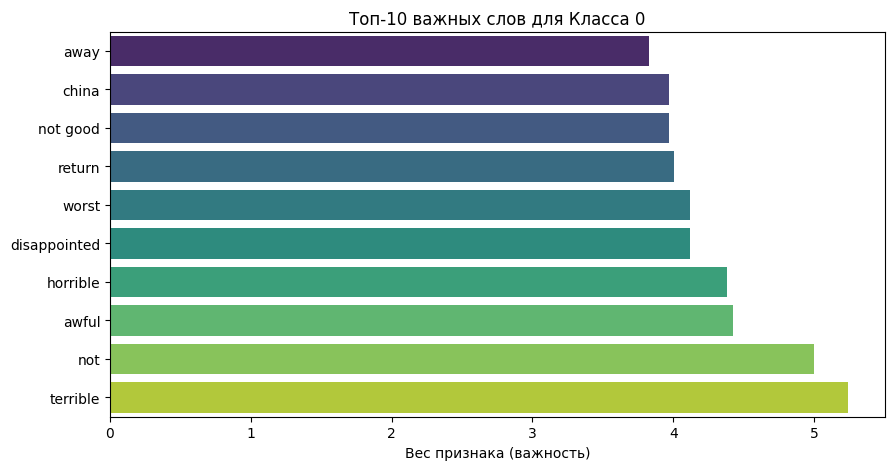

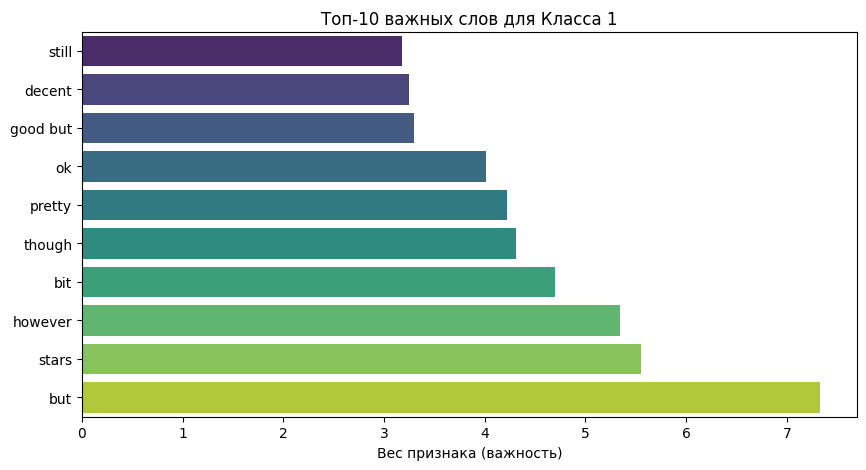

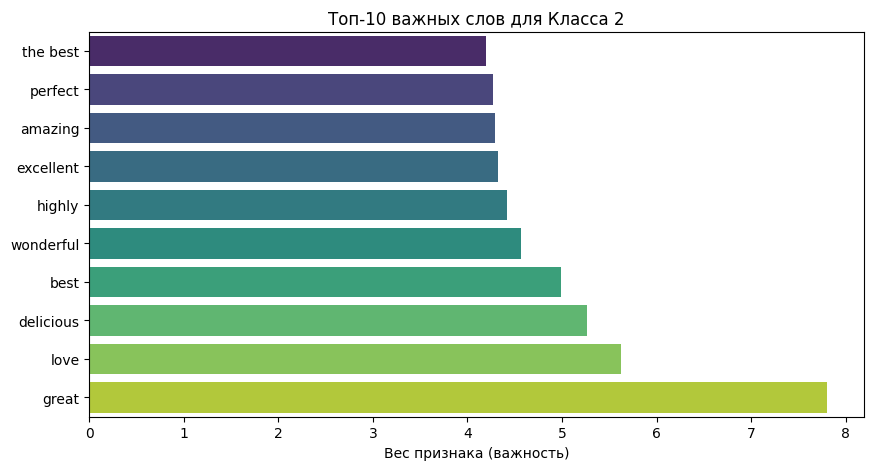

In [ ]:
plot_top_features(grid_tfidf)

# Feature Engineering


In [ ]:
def extract_manual_features(texts):
    features = []
    for text in texts:
        text = str(text)
        features.append(
            [
                len(text),
                len(text.split()),
                text.count("!"),
                text.count("?"),
                sum(1 for c in text if c.isupper()),
                len(re.findall(r"\d", text)),
            ]
        )
    return np.array(features)

In [ ]:
manual_feat_transformer = FunctionTransformer(extract_manual_features)

features_pipeline = FeatureUnion(
    [
        ("vectorizer", TfidfVectorizer(ngram_range=(1, 2), max_features=10000)),
        (
            "manual",
            Pipeline(
                [("extract", manual_feat_transformer), ("scale", StandardScaler())]
            ),
        ),
    ]
)

full_pipeline = Pipeline(
    [
        ("features", features_pipeline),
        ("classifier", LogisticRegression(max_iter=1000, solver="lbfgs")),
    ]
)

In [ ]:
full_pipeline.fit(X_train, y_train)

y_pred = full_pipeline.predict(X_test)
y_proba = full_pipeline.predict_proba(X_test)

print(f"Accuracy с доп. признаками: {accuracy_score(y_test, y_pred):.4f}")
print(f"Log Loss с доп. признаками: {log_loss(y_test, y_proba):.4f}")

Accuracy с доп. признаками: 0.7619
Log Loss с доп. признаками: 0.5779


In [ ]:
param_grid_final = {
    "features__vectorizer__ngram_range": [(1, 1), (1, 2)],
    "features__vectorizer__max_features": [7000, 5000],
    "classifier__C": [0.1, 1.0, 5.0, 10.0],
    "classifier__penalty": ["l1", "l2"],
}

In [ ]:
grid_final = GridSearchCV(
    full_pipeline,
    param_grid_final,
    cv=cv_strategy,
    scoring="accuracy",
    n_jobs=-1,
    verbose=2,
)

print("Запуск глобального поиска параметров.")
grid_final.fit(X_train, y_train)

Запуск глобального поиска параметров.
Fitting 5 folds for each of 32 candidates, totalling 160 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.1, 1.0, ...], 'classifier__penalty': ['l1', 'l2'], 'features__vectorizer__max_features': [7000, 5000], 'features__vectorizer__ngram_range': [(1, ...), (1, ...)]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the ve

In [67]:
print(f"Победившая комбинация: {grid_final.best_params_}")

best_model = grid_final.best_estimator_
test_acc = accuracy_score(y_test, best_model.predict(X_test))
test_ll = log_loss(y_test, best_model.predict_proba(X_test))

print(f"Результаты на тесте (TF-IDF):")
print(f"Accuracy: {test_acc:.4f}")
print(f"Log Loss: {test_ll:.4f}")

Победившая комбинация: {'classifier__C': 1.0, 'classifier__penalty': 'l2', 'features__vectorizer__max_features': 7000, 'features__vectorizer__ngram_range': (1, 2)}
Результаты на тесте (TF-IDF):
Accuracy: 0.7617
Log Loss: 0.5792


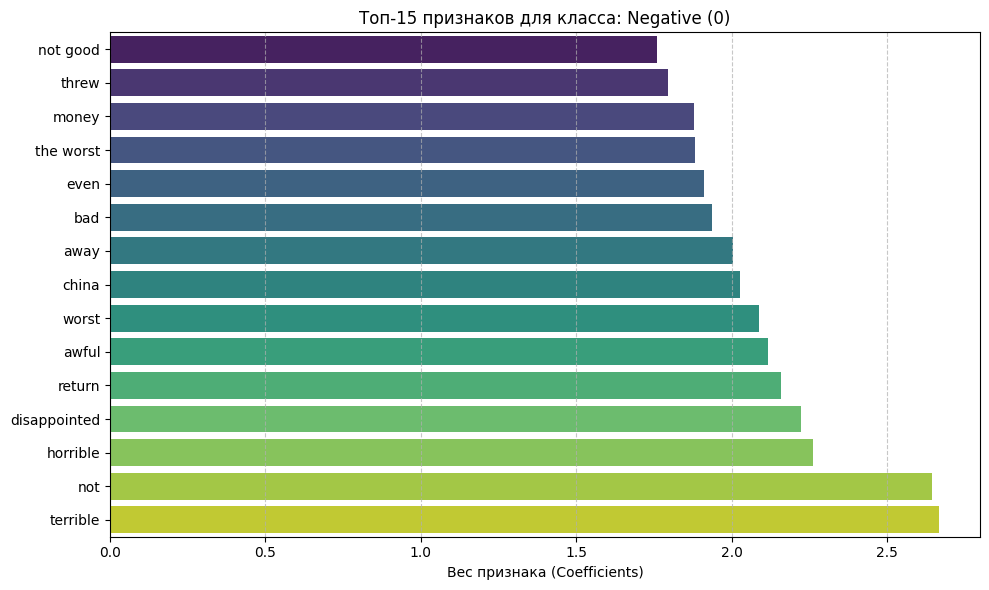

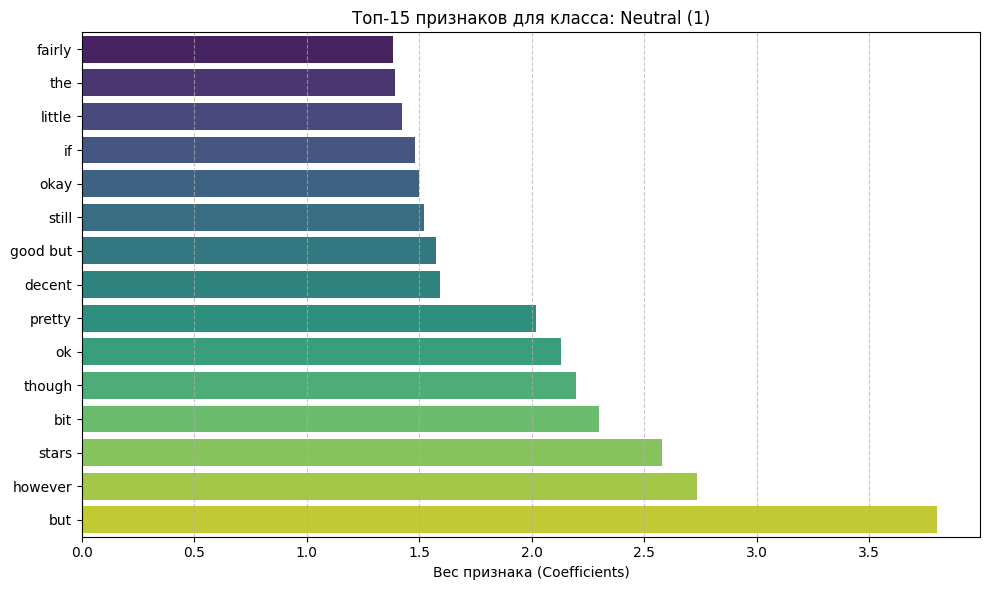

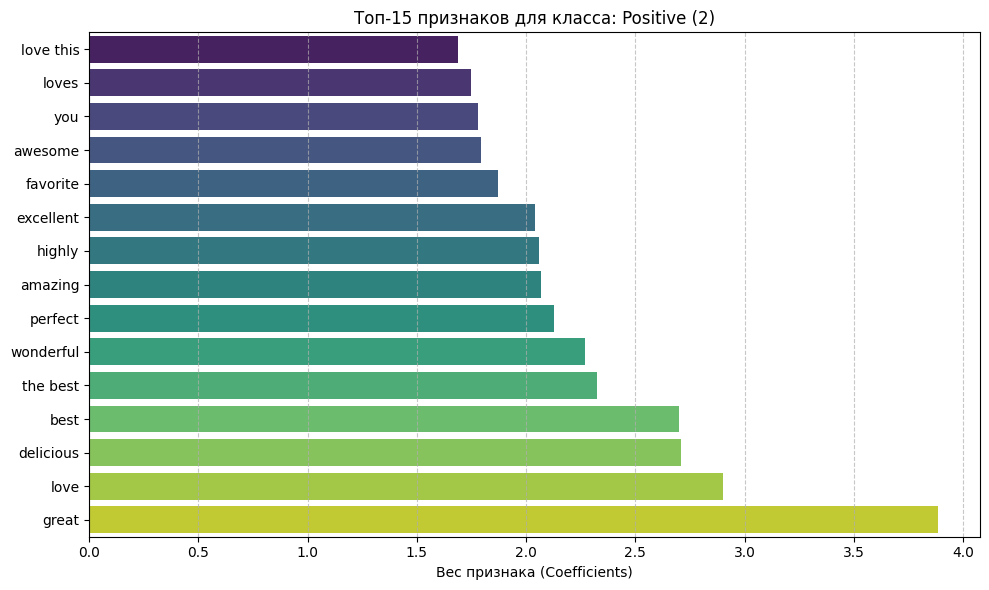

In [ ]:
def plot_final_model_importance(grid_result, n_top=15):
    best_pipe = grid_result.best_estimator_
    tfidf_features = (
        best_pipe.named_steps["features"].transformer_list[0][1].get_feature_names_out()
    )

    manual_features = [
        "len_text",
        "num_words",
        "exclamations",
        "questions",
        "caps_lock",
        "numbers",
    ]

    all_feature_names = np.concatenate([tfidf_features, manual_features])
    classifier = best_pipe.named_steps["classifier"]
    classes = ["Negative (0)", "Neutral (1)", "Positive (2)"]

    for i, class_name in enumerate(classes):
        coefs = classifier.coef_[i]
        top_indices = np.argsort(coefs)[-n_top:]
        names = [all_feature_names[idx] for idx in top_indices]
        values = coefs[top_indices]

        plt.figure(figsize=(10, 6))
        sns.barplot(x=values, y=names, palette="viridis")
        plt.title(f"Топ-{n_top} признаков для класса: {class_name}")
        plt.xlabel("Вес признака (Coefficients)")
        plt.grid(axis="x", linestyle="--", alpha=0.7)
        plt.tight_layout()
        plt.show()


plot_final_model_importance(grid_final)

Наши признаки не вошли в топ-10.


# DistilBert


In [96]:
import torch
from transformers import AutoTokenizer, AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
import numpy as np

In [97]:
model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

In [98]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
model.to(device)

cpu


DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSdpaAttention(
          (dropout): Dropout(p=0.1, inplace=False)
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=True)
          (lin2): L

In [99]:
model.eval()


def get_bert_embeddings(texts, batch_size=32):
    embeddings = []
    with torch.no_grad():
        for i in tqdm(
            range(0, len(texts), batch_size), desc="Extracting DISTILBERT features"
        ):
            batch_texts = texts[i : i + batch_size].tolist()
            inputs = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=128,
                return_tensors="pt",
            ).to(device)
            outputs = model(**inputs)
            cls_embeddings = outputs.last_hidden_state[:, 0, :].cpu().numpy()
            embeddings.append(cls_embeddings)

    return np.vstack(embeddings)

In [100]:
print("Получение эмбеддингов для Train.")
X_train_bert = get_bert_embeddings(X_train)

Получение эмбеддингов для Train.


Extracting DISTILBERT features: 100%|██████████| 344/344 [21:08<00:00,  3.69s/it]


In [101]:
print("Получение эмбеддингов для Test.")
X_test_bert = get_bert_embeddings(X_test)

Получение эмбеддингов для Test.


Extracting DISTILBERT features: 100%|██████████| 148/148 [07:38<00:00,  3.10s/it]


In [102]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_bert)
X_test_scaled = scaler.transform(X_test_bert)

In [ ]:
log_reg_bert = LogisticRegression(
    max_iter=1000,
    C=1.0,
    solver="lbfgs",
)
log_reg_bert.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [105]:
y_pred = log_reg_bert.predict(X_test_scaled)
y_proba = log_reg_bert.predict_proba(X_test_scaled)

print(f"DISTILBERT + Logistic Regression Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Log Loss: {log_loss(y_test, y_proba):.4f}")

DISTILBERT + Logistic Regression Results:
Accuracy: 0.7283
Log Loss: 0.6633


In [106]:
param_grid_bert = {
    "C": [0.1, 1.0, 5.0, 10.0],
    "penalty": ["l1", "l2"],
}

In [108]:
grid_bert = GridSearchCV(
    log_reg_bert,
    param_grid_bert,
    cv=cv_strategy,
    scoring="accuracy",
    n_jobs=-1,
    verbose=2,
)

print("Запуск поиска параметров.")
grid_bert.fit(X_train_scaled, y_train)

Запуск поиска параметров.
Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...max_iter=1000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1.0, ...], 'penalty': ['l1', 'l2']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score 

In [109]:
print(f"Победившая комбинация: {grid_bert.best_params_}")

best_model = grid_bert.best_estimator_
test_acc = accuracy_score(y_test, best_model.predict(X_test_scaled))
test_ll = log_loss(y_test, best_model.predict_proba(X_test_scaled))

print(f"Результаты на тесте (DistilBERT):")
print(f"Accuracy: {test_acc:.4f}")
print(f"Log Loss: {test_ll:.4f}")

Победившая комбинация: {'C': 0.1, 'penalty': 'l2'}
Результаты на тесте (DistilBERT):
Accuracy: 0.7358
Log Loss: 0.6301
